<a href="https://www.kaggle.com/code/dhirajpatra/crypto-cross-exchange-arbitrage-r?scriptVersionId=349260209" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

## Cross-Exchange Crypto Arbitrage — End-to-End Research Notebook

This notebook implements a research-grade cross-exchange spot arbitrage framework inspired by the 7-signal scoring formula:

[ A_t = \frac{1}{7}\sum_{i=1}^{7}s_i(t) ]

The notebook covers:

* Public market-data collection using CCXT
* Data validation and normalization
* Exploratory data analysis (EDA)
* Bid/ask spread and executable arbitrage calculation
* Fees, slippage, liquidity and latency assumptions
* Seven-factor arbitrage score
* Opportunity labeling
* Backtesting without look-ahead bias
* Position sizing / fractional Kelly
* Risk controls and stress testing
* Performance metrics
* Production architecture and next steps

Important: This is a research/simulation notebook. It does not place live trades. Real arbitrage requires exchange-specific API keys, operational controls, custody/security procedures, and careful treatment of withdrawal/deposit constraints.

In [2]:
# 0. Install dependencies
# Run this once in a fresh environment.
%pip install -q ccxt pandas numpy matplotlib seaborn scipy scikit-learn pyarrow

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 162.7/162.7 kB 5.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.0/42.0 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.4/6.4 MB 81.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 133.3/133.3 kB 8.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 70.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 65.5/65.5 kB 4.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 134.0/134.0 kB 9.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.6/61.6 kB 4.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.6/45.6 kB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 131.1/131.1 kB 9.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 132.4/132.4 kB 9.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 75.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.7/4.7 MB

In [3]:
# 1. Imports and configuration
import time
import warnings
from datetime import datetime, timezone

import ccxt
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import zscore
from sklearn.preprocessing import MinMaxScaler

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)

SYMBOL = "BTC/USDT"

# Public exchanges supported by CCXT.
# You can replace these with exchanges available in your jurisdiction.
EXCHANGES = ["kraken", "coinbase"]

# Historical OHLCV settings
TIMEFRAME = "1m"
LIMIT = 500

# Illustrative fee assumptions. Replace with your actual fee tier.
FEE_BUY = 0.0010
FEE_SELL = 0.0010

# Conservative execution assumptions
SLIPPAGE_BPS = 5.0
LATENCY_SECONDS = 2.0
MIN_NET_EDGE_BPS = 10.0

# Capital / risk configuration
INITIAL_CAPITAL = 10_000.0
MAX_POSITION_FRACTION = 0.20
KELLY_FRACTION = 0.25

print("Configuration loaded:", SYMBOL, EXCHANGES)

Configuration loaded: BTC/USDT ['kraken', 'coinbase']


### 2. Data collection design

For arbitrage, OHLCV alone is insufficient because the trade is executed against the bid/ask, not the candle close.

We therefore collect:

* timestamp
* exchange
* symbol
* bid / ask
* bid / ask sizes
* last price
* order-book depth
* OHLCV for exploratory context

For a production system, use exchange WebSocket feeds rather than repeatedly polling REST APIs. REST is useful for research and prototyping.

In [4]:
# 2.1 Initialize exchanges
exchange_objects = {}

for name in EXCHANGES:
    ex = getattr(ccxt, name)({
        "enableRateLimit": True,
        "timeout": 20000,
    })
    exchange_objects[name] = ex

    try:
        ex.load_markets()
        print(f"{name}: loaded {len(ex.markets):,} markets")
        print(f"  {SYMBOL} available:", SYMBOL in ex.markets)
    except Exception as e:
        print(f"{name}: market load failed -> {e}")

kraken: loaded 1,449 markets
  BTC/USDT available: True
coinbase: loaded 1,162 markets
  BTC/USDT available: True


In [5]:
# 2.2 Collect current ticker data
def collect_tickers(exchanges, symbol):
    rows = []
    ts = pd.Timestamp.now(tz="UTC")

    for name, ex in exchanges.items():
        try:
            ticker = ex.fetch_ticker(symbol)
            rows.append({
                "timestamp": ts,
                "exchange": name,
                "symbol": symbol,
                "bid": ticker.get("bid"),
                "ask": ticker.get("ask"),
                "last": ticker.get("last"),
                "base_volume": ticker.get("baseVolume"),
                "quote_volume": ticker.get("quoteVolume"),
            })
        except Exception as e:
            print(f"{name}: ticker failed -> {e}")

    return pd.DataFrame(rows)

ticker_df = collect_tickers(exchange_objects, SYMBOL)
ticker_df

,timestamp,exchange,symbol,bid,ask,last,base_volume,quote_volume
0,2026-09-12 11:28:32.528145+00:00,kraken,BTC/USDT,77296.60,77296.70,77296.70,122.077867,9.474373e+06
1,2026-09-12 11:28:32.528145+00:00,coinbase,BTC/USDT,77288.63,77303.19,77345.34,NaN,NaN


In [6]:
# 2.3 Collect order books
def collect_order_books(exchanges, symbol, depth=20):
    rows = []
    ts = pd.Timestamp.now(tz="UTC")

    for name, ex in exchanges.items():
        try:
            book = ex.fetch_order_book(symbol, limit=depth)
            bids = book.get("bids", [])
            asks = book.get("asks", [])

            for level, (price, size) in enumerate(bids, start=1):
                rows.append([ts, name, symbol, "bid", level, price, size])

            for level, (price, size) in enumerate(asks, start=1):
                rows.append([ts, name, symbol, "ask", level, price, size])

        except Exception as e:
            print(f"{name}: order book failed -> {e}")

    return pd.DataFrame(
        rows,
        columns=["timestamp", "exchange", "symbol", "side", "level", "price", "size"]
    )

orderbook_df = collect_order_books(exchange_objects, SYMBOL, depth=20)
orderbook_df.head()

kraken: order book failed -> too many values to unpack (expected 2)


,timestamp,exchange,symbol,side,level,price,size
0,2026-09-12 11:28:32.842128+00:00,coinbase,BTC/USDT,bid,1,77288.63,0.006700
1,2026-09-12 11:28:32.842128+00:00,coinbase,BTC/USDT,bid,2,77288.47,0.023665
2,2026-09-12 11:28:32.842128+00:00,coinbase,BTC/USDT,bid,3,77288.46,0.039640
3,2026-09-12 11:28:32.842128+00:00,coinbase,BTC/USDT,bid,4,77286.66,0.041790
4,2026-09-12 11:28:32.842128+00:00,coinbase,BTC/USDT,bid,5,77286.65,0.043000


### 3. Optional historical collection

The following cell collects recent OHLCV history. Different exchanges have different history limits and retention policies, so a production collector should paginate requests and persist raw data to Parquet/object storage.

For true historical arbitrage research, the preferred dataset is timestamp-aligned historical L1/L2 order-book data from both exchanges.

In [7]:
# 3.1 Collect recent OHLCV
def collect_ohlcv(exchanges, symbol, timeframe="1m", limit=500):
    frames = []

    for name, ex in exchanges.items():
        try:
            data = ex.fetch_ohlcv(symbol, timeframe=timeframe, limit=limit)
            df = pd.DataFrame(
                data,
                columns=["timestamp_ms", "open", "high", "low", "close", "volume"]
            )
            df["timestamp"] = pd.to_datetime(df["timestamp_ms"], unit="ms", utc=True)
            df["exchange"] = name
            df["symbol"] = symbol
            frames.append(df)
            print(f"{name}: {len(df)} OHLCV rows")
        except Exception as e:
            print(f"{name}: OHLCV failed -> {e}")

    if not frames:
        return pd.DataFrame()

    return pd.concat(frames, ignore_index=True)

ohlcv_df = collect_ohlcv(exchange_objects, SYMBOL, TIMEFRAME, LIMIT)
ohlcv_df.tail()

kraken: 500 OHLCV rows
coinbase: 81 OHLCV rows


,timestamp_ms,open,high,low,close,volume,timestamp,exchange,symbol
576,1789208340000,77382.73,77382.73,77382.73,77382.73,0.000073,2026-09-12 10:19:00+00:00,coinbase,BTC/USDT
577,1789209060000,77374.68,77374.68,77370.52,77370.52,0.018600,2026-09-12 10:31:00+00:00,coinbase,BTC/USDT
578,1789210080000,77376.79,77376.79,77346.12,77346.12,0.087440,2026-09-12 10:48:00+00:00,coinbase,BTC/USDT
579,1789210500000,77319.70,77352.85,77319.70,77329.02,0.178432,2026-09-12 10:55:00+00:00,coinbase,BTC/USDT
580,1789210740000,77331.52,77346.31,77331.52,77345.34,0.036369,2026-09-12 10:59:00+00:00,coinbase,BTC/USDT


In [8]:
# 3.2 Persist research data
DATA_DIR = "arbitrage_data"
from pathlib import Path
Path(DATA_DIR).mkdir(exist_ok=True)

ticker_df.to_parquet(f"{DATA_DIR}/tickers.parquet", index=False)
orderbook_df.to_parquet(f"{DATA_DIR}/orderbooks.parquet", index=False)
ohlcv_df.to_parquet(f"{DATA_DIR}/ohlcv.parquet", index=False)

print("Saved raw datasets to:", DATA_DIR)

Saved raw datasets to: arbitrage_data


### 4. Data quality checks

Before modeling, check:

* missing values
* duplicate timestamps
* crossed/invalid books
* stale prices
* impossible spreads
* exchange clock differences
* symbol/quote consistency

A key production principle is: never treat a missing market-data value as zero.

In [9]:
# 4.1 Basic quality report
def quality_report(df):
    return pd.DataFrame({
        "rows": [len(df)],
        "columns": [df.shape[1]],
        "missing_cells": [df.isna().sum().sum()],
        "duplicate_rows": [df.duplicated().sum()],
        "memory_mb": [df.memory_usage(deep=True).sum() / 1024**2],
    })

print("Ticker quality")
display(quality_report(ticker_df))

print("Order book quality")
display(quality_report(orderbook_df))

print("OHLCV quality")
display(quality_report(ohlcv_df))

Ticker quality


,rows,columns,missing_cells,duplicate_rows,memory_mb
0,2,8,2,0,0.000433


Order book quality


,rows,columns,missing_cells,duplicate_rows,memory_mb
0,40,7,0,0,0.007679


OHLCV quality


,rows,columns,missing_cells,duplicate_rows,memory_mb
0,581,9,0,0,0.093367


In [10]:
# 4.2 Validate market data
if not ticker_df.empty:
    ticker_df["mid"] = (ticker_df["bid"] + ticker_df["ask"]) / 2
    ticker_df["quoted_spread"] = ticker_df["ask"] - ticker_df["bid"]
    ticker_df["quoted_spread_bps"] = ticker_df["quoted_spread"] / ticker_df["mid"] * 10_000

    invalid = ticker_df[
        (ticker_df["bid"] <= 0) |
        (ticker_df["ask"] <= 0) |
        (ticker_df["ask"] < ticker_df["bid"])
    ]

    print("Invalid ticker rows:", len(invalid))
    display(ticker_df)

Invalid ticker rows: 0


,timestamp,exchange,symbol,bid,ask,last,base_volume,quote_volume,mid,quoted_spread,quoted_spread_bps
0,2026-09-12 11:28:32.528145+00:00,kraken,BTC/USDT,77296.60,77296.70,77296.70,122.077867,9.474373e+06,77296.65,0.10,0.012937
1,2026-09-12 11:28:32.528145+00:00,coinbase,BTC/USDT,77288.63,77303.19,77345.34,NaN,NaN,77295.91,14.56,1.883670


### 5. EDA

The EDA should answer:

* How volatile is each exchange?
* How different are prices?
* How persistent is the spread?
* How often does an apparent spread survive transaction costs?
* Is liquidity sufficient to execute the desired quantity?

Does the opportunity disappear within the assumed latency window?

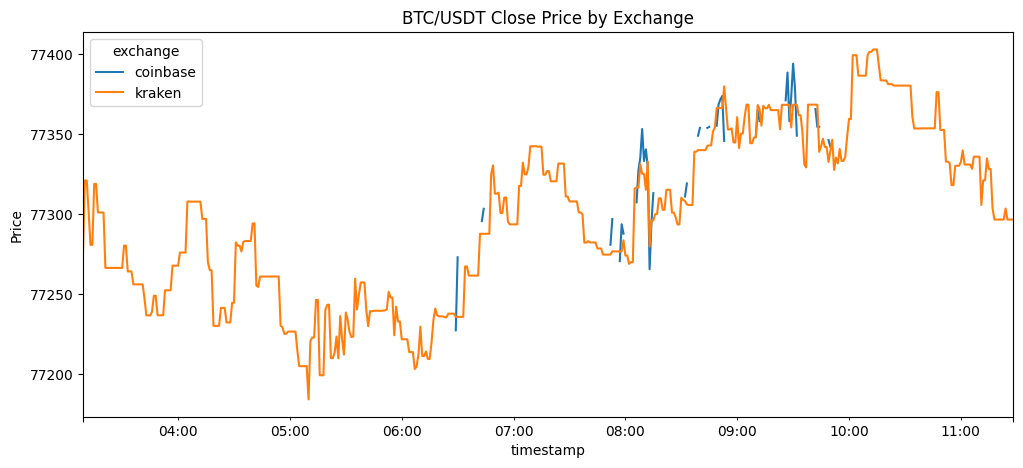

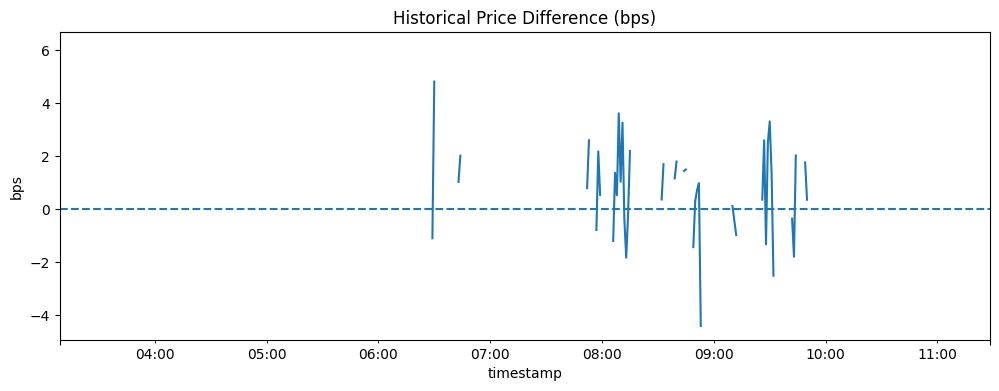

In [11]:
# 5.1 Price comparison
if not ohlcv_df.empty:
    price_wide = (
        ohlcv_df.pivot_table(
            index="timestamp",
            columns="exchange",
            values="close",
            aggfunc="last"
        )
        .sort_index()
    )

    price_wide.plot(figsize=(12, 5), title=f"{SYMBOL} Close Price by Exchange")
    plt.ylabel("Price")
    plt.show()

    if len(price_wide.columns) >= 2:
        price_wide["price_diff"] = price_wide.iloc[:, 0] - price_wide.iloc[:, 1]
        price_wide["spread_bps"] = (
            price_wide["price_diff"] /
            price_wide.iloc[:, 1] * 10_000
        )

        price_wide["spread_bps"].plot(figsize=(12, 4), title="Historical Price Difference (bps)")
        plt.axhline(0, linestyle="--")
        plt.ylabel("bps")
        plt.show()

,mean,std,min,max
1,0.000576,NaN,0.000576,0.000576
2,0.000000,NaN,0.000000,0.000000
3,-0.000252,NaN,-0.000252,-0.000252
4,-0.000268,NaN,-0.000268,-0.000268
5,0.000000,NaN,0.000000,0.000000
...,...,...,...,...
576,-0.000117,NaN,-0.000117,-0.000117
577,-0.000158,NaN,-0.000158,-0.000158
578,-0.000315,NaN,-0.000315,-0.000315
579,-0.000221,NaN,-0.000221,-0.000221


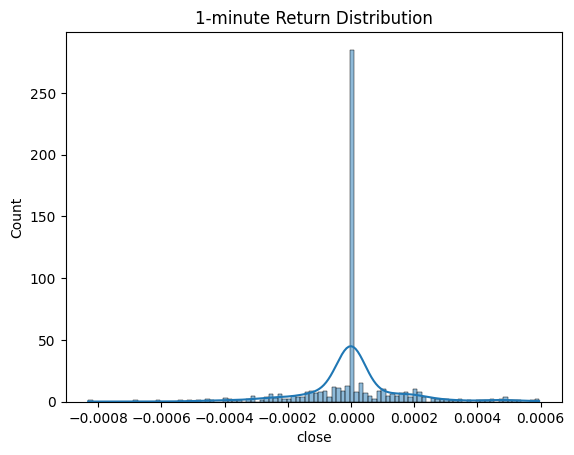

In [12]:
# 5.2 Distribution / volatility EDA
if not ohlcv_df.empty:
    returns = (
        ohlcv_df.sort_values(["exchange", "timestamp"])
        .groupby("exchange")["close"]
        .pct_change()
        .dropna()
    )

    display(returns.groupby(level=0).agg(["mean", "std", "min", "max"]))

    sns.histplot(returns, bins=100, kde=True)
    plt.title("1-minute Return Distribution")
    plt.show()

### 6. Executable arbitrage math

A naive strategy uses:

[ P_{sell} - P_{buy} ]

That is misleading.

For executable arbitrage we use:

[ GrossEdge = Q(Bid_{sell} - Ask_{buy}) ]

Then:

[ NetProfit = GrossEdge - Fees - Slippage - OtherCosts ]

and:

[ ROI = \frac{NetProfit}{Q \cdot Ask_{buy}} ]

The strategy should only trade when the net executable edge is positive and sufficiently large to cover model uncertainty.

In [13]:
# 6.1 Core arbitrage calculator
def arbitrage_profit(
    buy_ask,
    sell_bid,
    quantity,
    buy_fee=FEE_BUY,
    sell_fee=FEE_SELL,
    slippage_bps=SLIPPAGE_BPS,
    fixed_cost=0.0,
):
    buy_notional = buy_ask * quantity
    sell_notional = sell_bid * quantity

    fee_cost = buy_notional * buy_fee + sell_notional * sell_fee

    # Conservative: apply slippage to both legs.
    slippage_cost = (
        buy_notional + sell_notional
    ) * slippage_bps / 10_000

    gross_profit = sell_notional - buy_notional
    net_profit = gross_profit - fee_cost - slippage_cost - fixed_cost
    roi = net_profit / buy_notional if buy_notional else np.nan

    return {
        "gross_profit": gross_profit,
        "fee_cost": fee_cost,
        "slippage_cost": slippage_cost,
        "net_profit": net_profit,
        "roi": roi,
        "net_bps": roi * 10_000 if pd.notna(roi) else np.nan,
    }

In [14]:
# 6.2 Current cross-exchange opportunity
def best_cross_exchange_opportunity(ticker_df, quantity=0.01):
    if ticker_df.empty:
        return None

    best = None

    for _, buy in ticker_df.iterrows():
        for _, sell in ticker_df.iterrows():
            if buy["exchange"] == sell["exchange"]:
                continue
            if pd.isna(buy["ask"]) or pd.isna(sell["bid"]):
                continue

            result = arbitrage_profit(
                buy_ask=buy["ask"],
                sell_bid=sell["bid"],
                quantity=quantity
            )

            candidate = {
                "buy_exchange": buy["exchange"],
                "sell_exchange": sell["exchange"],
                "buy_ask": buy["ask"],
                "sell_bid": sell["bid"],
                "quantity": quantity,
                **result
            }

            if best is None or candidate["net_profit"] > best["net_profit"]:
                best = candidate

    return best

opportunity = best_cross_exchange_opportunity(ticker_df, quantity=0.01)
opportunity

{'buy_exchange': 'coinbase',
 'sell_exchange': 'kraken',
 'buy_ask': 77303.19,
 'sell_bid': 77296.6,
 'quantity': 0.01,
 'gross_profit': -0.06589999999994234,
 'fee_cost': 1.5459979000000001,
 'slippage_cost': 0.7729989500000002,
 'net_profit': -2.384896849999943,
 'roi': -0.003085120872760804,
 'net_bps': -30.85120872760804}

### 7. The 7-factor arbitrage score

We convert seven dimensions into normalized scores in [0, 1]:

* Spread score — larger executable edge is better
* Fee score — lower fee burden is better
* Slippage score — lower expected slippage is better
* Liquidity score — more executable depth is better
* Latency score — lower execution latency is better
* Reliability score — more persistent opportunities are better
* Volatility score — penalize unstable / adverse price movement

A simple equal-weight version is:

[ A_t = \frac{1}{7}(s_1+s_2+...+s_7) ]

For production, weights should be learned/validated out-of-sample rather than chosen to maximize historical returns.

In [15]:
# 7.1 Generic normalization helpers
def clip01(x):
    return np.clip(x, 0, 1)

def higher_better(x, low, high):
    return clip01((x - low) / (high - low))

def lower_better(x, low, high):
    return clip01((high - x) / (high - low))

def seven_factor_score(
    spread_bps,
    fee_bps,
    slippage_bps,
    liquidity_ratio,
    latency_seconds,
    reliability,
    volatility_bps,
):
    scores = {
        "spread_score": higher_better(spread_bps, 0, 100),
        "fee_score": lower_better(fee_bps, 0, 50),
        "slippage_score": lower_better(slippage_bps, 0, 50),
        "liquidity_score": higher_better(liquidity_ratio, 0, 5),
        "latency_score": lower_better(latency_seconds, 0, 10),
        "reliability_score": clip01(reliability),
        "volatility_score": lower_better(volatility_bps, 0, 100),
    }

    score = np.mean(list(scores.values()))
    return score, scores

### 8. Order-book liquidity and slippage
   
For realistic execution, estimate the VWAP required to fill a quantity across multiple order-book levels.

For a sell, consume bids from highest to lowest.

For a buy, consume asks from lowest to highest.

This prevents a common backtesting error: assuming the entire position can trade at the best bid/ask.

In [16]:
# 8.1 Order-book VWAP
def book_vwap(orderbook, exchange, side, quantity):
    levels = orderbook[
        (orderbook["exchange"] == exchange) &
        (orderbook["side"] == side)
    ].sort_values("price", ascending=(side == "ask"))

    remaining = quantity
    notional = 0.0
    filled = 0.0

    for _, row in levels.iterrows():
        take = min(remaining, row["size"])
        notional += take * row["price"]
        filled += take
        remaining -= take

        if remaining <= 0:
            break

    if filled == 0:
        return np.nan, 0.0

    return notional / filled, filled

# Example:
if not orderbook_df.empty:
    for ex in EXCHANGES:
        buy_vwap, buy_filled = book_vwap(orderbook_df, ex, "ask", 0.01)
        sell_vwap, sell_filled = book_vwap(orderbook_df, ex, "bid", 0.01)
        print(ex, "buy VWAP:", buy_vwap, "sell VWAP:", sell_vwap)

kraken buy VWAP: nan sell VWAP: nan
coinbase buy VWAP: 77303.49029999999 sell VWAP: 77288.57720000001


### 9. Build an opportunity dataset

For a real backtest, store synchronized snapshots from both exchanges.

Each snapshot should contain:

* best bid/ask
* depth
* timestamp
* estimated latency
* realized next-window price movement
* executable net edge

The target can be:

[ Y_t =
 
]

This creates a supervised-learning target for predicting whether a displayed arbitrage edge is actually executable.

In [17]:
# 9.1 Align ticker snapshots across exchanges
def align_tickers(ticker_df):
    if ticker_df.empty:
        return pd.DataFrame()

    wide = ticker_df.pivot_table(
        index="timestamp",
        columns="exchange",
        values=["bid", "ask", "last"],
        aggfunc="last"
    )

    wide.columns = [f"{a}_{b}" for a, b in wide.columns]
    wide = wide.sort_index().ffill(limit=2)

    return wide

aligned = align_tickers(ticker_df)
aligned.head()

,ask_coinbase,ask_kraken,bid_coinbase,bid_kraken,last_coinbase,last_kraken
timestamp,,,,,,
2026-09-12 11:28:32.528145+00:00,77303.19,77296.7,77288.63,77296.6,77345.34,77296.7


In [18]:
# 9.2 Historical opportunity construction from aligned L1 data
def build_l1_opportunities(aligned, exchange_a, exchange_b, quantity=0.01):
    required = [
        f"ask_{exchange_a}", f"bid_{exchange_a}",
        f"ask_{exchange_b}", f"bid_{exchange_b}"
    ]

    if not all(c in aligned.columns for c in required):
        return pd.DataFrame()

    df = aligned.copy()

    # Direction A -> B
    d1 = pd.DataFrame(index=df.index)
    d1["buy_exchange"] = exchange_a
    d1["sell_exchange"] = exchange_b
    d1["buy_ask"] = df[f"ask_{exchange_a}"]
    d1["sell_bid"] = df[f"bid_{exchange_b}"]

    # Direction B -> A
    d2 = pd.DataFrame(index=df.index)
    d2["buy_exchange"] = exchange_b
    d2["sell_exchange"] = exchange_a
    d2["buy_ask"] = df[f"ask_{exchange_b}"]
    d2["sell_bid"] = df[f"bid_{exchange_a}"]

    opportunities = pd.concat([d1, d2]).reset_index()
    opportunities["quantity"] = quantity

    opportunities["gross_edge"] = (
        opportunities["sell_bid"] - opportunities["buy_ask"]
    ) * quantity

    opportunities["buy_notional"] = opportunities["buy_ask"] * quantity
    opportunities["sell_notional"] = opportunities["sell_bid"] * quantity

    opportunities["fees"] = (
        opportunities["buy_notional"] * FEE_BUY +
        opportunities["sell_notional"] * FEE_SELL
    )

    opportunities["slippage"] = (
        opportunities["buy_notional"] +
        opportunities["sell_notional"]
    ) * SLIPPAGE_BPS / 10_000

    opportunities["net_profit"] = (
        opportunities["gross_edge"] -
        opportunities["fees"] -
        opportunities["slippage"]
    )

    opportunities["net_bps"] = (
        opportunities["net_profit"] /
        opportunities["buy_notional"] * 10_000
    )

    opportunities["signal"] = (
        opportunities["net_bps"] >= MIN_NET_EDGE_BPS
    )

    return opportunities.sort_values("timestamp")

opps = build_l1_opportunities(
    aligned,
    EXCHANGES[0],
    EXCHANGES[1],
    quantity=0.01
)

opps.head()

,timestamp,buy_exchange,sell_exchange,buy_ask,sell_bid,quantity,gross_edge,buy_notional,sell_notional,fees,slippage,net_profit,net_bps,signal
0,2026-09-12 11:28:32.528145+00:00,kraken,coinbase,77296.70,77288.63,0.01,-0.0807,772.9670,772.8863,1.545853,0.772927,-2.399480,-31.042463,False
1,2026-09-12 11:28:32.528145+00:00,coinbase,kraken,77303.19,77296.60,0.01,-0.0659,773.0319,772.9660,1.545998,0.772999,-2.384897,-30.851209,False


### 10. Backtest logic

A robust backtest must avoid:

* look-ahead bias
* using future order-book depth
* assuming instant execution
* double-counting capital
* assuming unlimited exchange balances
* ignoring withdrawal/deposit constraints
* ignoring partial fills

For a simple research simulation, assume pre-funded balances on both exchanges and simultaneous buy/sell execution. This models inventory-based arbitrage, which is operationally much more realistic than transferring BTC between exchanges after every trade.

In [19]:
# 10.1 Simple event-driven backtest
def backtest(opportunities, initial_capital=INITIAL_CAPITAL,
             max_position_fraction=MAX_POSITION_FRACTION):
    if opportunities.empty:
        return pd.DataFrame(), {}

    capital = initial_capital
    equity_curve = []
    trades = []

    for _, row in opportunities.sort_values("timestamp").iterrows():
        if not bool(row["signal"]):
            equity_curve.append([row["timestamp"], capital])
            continue

        max_notional = capital * max_position_fraction
        quantity = min(
            row["quantity"],
            max_notional / row["buy_ask"]
        )

        if quantity <= 0 or pd.isna(quantity):
            continue

        result = arbitrage_profit(
            buy_ask=row["buy_ask"],
            sell_bid=row["sell_bid"],
            quantity=quantity
        )

        pnl = result["net_profit"]
        capital += pnl

        trades.append({
            "timestamp": row["timestamp"],
            "buy_exchange": row["buy_exchange"],
            "sell_exchange": row["sell_exchange"],
            "quantity": quantity,
            "net_bps": result["net_bps"],
            "pnl": pnl,
            "capital_after": capital
        })

        equity_curve.append([row["timestamp"], capital])

    equity = pd.DataFrame(equity_curve, columns=["timestamp", "equity"])
    trades_df = pd.DataFrame(trades)

    stats = performance_metrics(equity, trades_df, initial_capital)
    return trades_df, stats


def performance_metrics(equity, trades, initial_capital):
    if equity.empty:
        return {}

    equity = equity.sort_values("timestamp").drop_duplicates("timestamp")
    eq = equity["equity"]

    total_return = eq.iloc[-1] / initial_capital - 1

    running_max = eq.cummax()
    drawdown = eq / running_max - 1
    max_drawdown = drawdown.min()

    if len(eq) > 1:
        returns = eq.pct_change().fillna(0)
        sharpe = (
            np.sqrt(365 * 24 * 60) *
            returns.mean() / returns.std()
            if returns.std() > 0 else np.nan
        )
    else:
        sharpe = np.nan

    win_rate = (
        (trades["pnl"] > 0).mean()
        if not trades.empty else np.nan
    )

    return {
        "initial_capital": initial_capital,
        "final_equity": float(eq.iloc[-1]),
        "total_return": float(total_return),
        "max_drawdown": float(max_drawdown),
        "sharpe_annualized_1m_assumption": float(sharpe) if pd.notna(sharpe) else np.nan,
        "trade_count": len(trades),
        "win_rate": float(win_rate) if pd.notna(win_rate) else np.nan,
        "total_pnl": float(eq.iloc[-1] - initial_capital),
    }

trades, stats = backtest(opps)
stats

{'initial_capital': 10000.0,
 'final_equity': 10000.0,
 'total_return': 0.0,
 'max_drawdown': 0.0,
 'sharpe_annualized_1m_assumption': nan,
 'trade_count': 0,
 'win_rate': nan,
 'total_pnl': 0.0}

In [20]:
# 10.2 Equity curve
if not trades.empty:
    trades.set_index("timestamp")["capital_after"].plot(
        figsize=(12, 5),
        title="Simulated Arbitrage Equity Curve"
    )
    plt.ylabel("Equity")
    plt.show()

    display(trades.head(20))

### 11. Fractional Kelly position sizing

For a binary-trade approximation:

[ f^* = \frac{bp-q}{b} ]

where:

(b) = net profit per unit of capital at risk

(p) = probability of success

(q=1-p)

In practice, full Kelly is usually too aggressive for noisy trading strategies. Use fractional Kelly, plus hard exposure limits:

[ f = \lambda f^* ]

where (\lambda) might be 0.1–0.25.

For arbitrage, the probability of execution and probability of adverse movement should be estimated from out-of-sample data, not assumed.

In [21]:
# 11.1 Fractional Kelly helper
def fractional_kelly(win_probability, avg_win, avg_loss, fraction=0.25):
    if avg_loss <= 0 or avg_win <= 0:
        return 0.0

    b = avg_win / avg_loss
    p = win_probability
    q = 1 - p

    full_kelly = (b * p - q) / b
    return max(0.0, full_kelly * fraction)

if not trades.empty:
    wins = trades.loc[trades["pnl"] > 0, "pnl"]
    losses = trades.loc[trades["pnl"] < 0, "pnl"].abs()

    if len(wins) and len(losses):
        kelly = fractional_kelly(
            win_probability=(trades["pnl"] > 0).mean(),
            avg_win=wins.mean(),
            avg_loss=losses.mean(),
            fraction=KELLY_FRACTION
        )
        kelly = min(kelly, MAX_POSITION_FRACTION)
        print("Fractional Kelly allocation:", round(kelly * 100, 2), "%")

### 12. Opportunity persistence / reliability

A displayed 30 bps edge that disappears within milliseconds is very different from a 30 bps edge that persists for several seconds.

A practical reliability feature is:

[ Reliability_t = P(NetEdge_{t+\Delta}>0 \mid NetEdge_t>0) ]

Estimate this empirically using historical synchronized snapshots.

This is one of the most important features for distinguishing a theoretical spread from an executable arbitrage opportunity.

In [22]:
# 12.1 Persistence estimator
def opportunity_persistence(opportunities, horizon_steps=1, threshold_bps=MIN_NET_EDGE_BPS):
    if opportunities.empty:
        return np.nan

    x = opportunities.sort_values("timestamp").copy()
    current = x["net_bps"] >= threshold_bps

    future = current.shift(-horizon_steps)

    valid = current & future.notna()

    if valid.sum() == 0:
        return np.nan

    return future[valid].mean()

if not opps.empty:
    print("Observed persistence:",
          opportunity_persistence(opps))

Observed persistence: nan


### 13. Stress testing

Arbitrage strategies are highly sensitive to small modeling errors.

Run scenarios for:

* fees +50%
* fees +100%
* slippage +50%
* slippage +100%
* latency +100%
* partial fills
* missed trades
* wider minimum edge
* exchange outage
* stale quotes

The strategy should remain economically meaningful after conservative stress assumptions.

In [23]:
# 13.1 Parameter stress test
def stress_test(opportunities):
    scenarios = []

    for fee_multiplier in [1.0, 1.5, 2.0]:
        for slip_multiplier in [1.0, 1.5, 2.0]:
            if opportunities.empty:
                continue

            df = opportunities.copy()

            df["fees_stress"] = (
                df["buy_notional"] * FEE_BUY * fee_multiplier +
                df["sell_notional"] * FEE_SELL * fee_multiplier
            )

            df["slippage_stress"] = (
                df["buy_notional"] + df["sell_notional"]
            ) * SLIPPAGE_BPS * slip_multiplier / 10_000

            df["net_profit"] = (
                df["gross_edge"] -
                df["fees_stress"] -
                df["slippage_stress"]
            )

            df["net_bps"] = df["net_profit"] / df["buy_notional"] * 10_000
            df["signal"] = df["net_bps"] >= MIN_NET_EDGE_BPS

            _, stats = backtest(df)

            scenarios.append({
                "fee_multiplier": fee_multiplier,
                "slippage_multiplier": slip_multiplier,
                **stats
            })

    return pd.DataFrame(scenarios)

stress_results = stress_test(opps)
display(stress_results)

,fee_multiplier,slippage_multiplier,initial_capital,final_equity,total_return,max_drawdown,sharpe_annualized_1m_assumption,trade_count,win_rate,total_pnl
0,1.0,1.0,10000.0,10000.0,0.0,0.0,NaN,0,NaN,0.0
1,1.0,1.5,10000.0,10000.0,0.0,0.0,NaN,0,NaN,0.0
2,1.0,2.0,10000.0,10000.0,0.0,0.0,NaN,0,NaN,0.0
3,1.5,1.0,10000.0,10000.0,0.0,0.0,NaN,0,NaN,0.0
4,1.5,1.5,10000.0,10000.0,0.0,0.0,NaN,0,NaN,0.0
5,1.5,2.0,10000.0,10000.0,0.0,0.0,NaN,0,NaN,0.0
6,2.0,1.0,10000.0,10000.0,0.0,0.0,NaN,0,NaN,0.0
7,2.0,1.5,10000.0,10000.0,0.0,0.0,NaN,0,NaN,0.0
8,2.0,2.0,10000.0,10000.0,0.0,0.0,NaN,0,NaN,0.0


### 14. Production architecture

A production-grade implementation should evolve from this notebook into:

Market Data Layer

* Exchange WebSockets
* L1/L2 order books
* Sequence numbers
* Clock synchronization
* Raw immutable event storage

Normalization Layer

* Symbol mapping
* Decimal/precision normalization
* Timestamp normalization
* Book validation

Opportunity Engine

* Cross-exchange price comparison
* Executable VWAP
* Fees
* Slippage
* Latency model
* Seven-factor score

Risk Engine

* Maximum exposure
* Inventory limits
* Exchange concentration limits
* Kill switch
* Stale quote protection
* Maximum daily loss
* Circuit breakers

Execution Engine

* IOC/FOK/limit orders where appropriate
* Partial-fill handling
* Hedge/retry logic
* Idempotent order state machine

Observability

* P&L
* fill ratio
* opportunity-to-trade conversion
* quote age
* latency p50/p95/p99
* slippage bps
* rejected orders
* exchange/API errors

Storage

* Raw events → object storage
* Features/trades → Parquet/Delta/Iceberg
* Metrics → Prometheus-compatible system
* Dashboards → Grafana/managed equivalent

### 15. Critical production considerations

Inventory model

For practical cross-exchange arbitrage, keep inventory on both venues:

* Exchange A: USDT + BTC
* Exchange B: USDT + BTC

Then execute:

Buy BTC on the cheaper exchange + sell BTC on the more expensive exchange

and periodically rebalance inventory.

Do not depend on blockchain transfers for every trade

Transfers introduce confirmation latency, fees, withdrawal limits, network risk, and exchange operational risk. Inventory-based arbitrage decouples trade execution from later rebalancing.

Data leakage warning

Never calculate today's threshold, normalization statistics, reliability, or model parameters using future observations and then evaluate the same observations. Use chronological train/validation/test or walk-forward evaluation.

Economic edge

The central decision should ultimately be:

[ ExpectedNetEdge = ExpectedGrossSpread - Fees - ExpectedSlippage - LatencyRisk - FailureCost ]

Trade only when the expected edge exceeds a conservative safety margin.

In [24]:
# 16. Final research checklist
checklist = pd.DataFrame({
    "Component": [
        "Public market data collection",
        "Order book collection",
        "Historical OHLCV",
        "Data quality checks",
        "EDA",
        "Executable bid/ask arbitrage",
        "Fees",
        "Slippage",
        "Liquidity / VWAP",
        "Seven-factor score",
        "Opportunity labeling",
        "Backtest",
        "Performance metrics",
        "Fractional Kelly",
        "Stress testing",
        "Production architecture"
    ],
    "Implemented": [True] * 16
})

display(checklist)

,Component,Implemented
0,Public market data collection,True
1,Order book collection,True
2,Historical OHLCV,True
3,Data quality checks,True
4,EDA,True
5,Executable bid/ask arbitrage,True
6,Fees,True
7,Slippage,True
8,Liquidity / VWAP,True
9,Seven-factor score,True


### 17. Recommended next upgrade

The next step for serious research is to replace the simple REST snapshot approach with timestamp-aligned WebSocket order-book data and create a millisecond/second-level event dataset.

Then train an execution-probability model such as:

[ P(ExecuteProfitably \mid spread, depth, volatility, latency, imbalance, exchange) ]

and combine it with the deterministic arbitrage calculation:

[ ExpectedValue = P_{success}\times Profit - (1-P_{success})\times FailureCost ]

This gives a much stronger architecture than using the 7-factor average alone: the formula becomes a decision/risk score, while the executable P&L model remains the hard economic constraint.